# Calculating Cutting Power in Turning Processes

**Machine process performed**: facing process in the lathe

## Parameters

* initial diameter $D_i = 30\,\mathrm{mm}$
* cutting speed $v_c = 100\,\mathrm{m/min}$
* feed per revolution $f = 0.5\,\mathrm{mm}$
* depth of cut $a_p = 1 \,\mathrm{mm}$ (I've assumed by myself a reasonable value) 
* position angle $k_r = \pi/6$
* maximum spindle speed $N = 10000\,\mathrm{rpm}$
* cutting specific energy $K_c = 700\,\mathrm{MPa}$

Create the following machining history of the **cutting power**:

* $t_0$: moment when the tool touches th piece
* $t_1$: the tool is fully engaged 
* $t_2$: the time when the spindle spped is maximum
* $t_3$: finishing the machining in the center of the part

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Parameters
Di = 30          # mm
vc = 100 * 10**3 # mm/min (100 m/min)
f = 0.5          # mm/rev
kr = np.pi / 6   # rad
N_max = 10000     # rev/min (rpm)
Kc = 700         # N/mm^2 (equivalent to MPa)

In [6]:
# Numerical parameters
dt = 1/(4*N_max/60) # Time step in seconds
t0 = 0.1            # Contact time in seconds

# t <= t0: ie till then the tool isn't engaged

t = np.arange(0, t0, dt).tolist()
Pc = np.zeros_like(t).tolist()  # Watts
N_values = np.zeros_like(t).tolist()    # rpm; undefined before contact
vc_values = np.zeros_like(t).tolist()   # mm/min; undefined before contact

# Engagement phase

r = 0.0       # (mm) Initial radius of the tool engagement
t_i = t0

t1 = None
t2 = None

while r < Di/2:
    N_i = min(vc / (np.pi * (Di - 2*r)), N_max)  # rpm
    ap_i = min(r, f) * np.tan(kr)   # mm
    vc_i = vc if N_i < N_max else np.pi * (Di - 2*r) * N_i  # mm/min
    A_i = 0.5 * ap_i * min(r, f)    # mm^2: assuming a triangular model for the engagement area
    
    t.append(t_i)
    N_values.append(N_i)
    vc_values.append(vc_i)
    Pc.append(Kc * A_i * vc_i/(60*1000))

    if t1 is None and r >= f:
        t1 = t_i

    if t2 is None and N_i >= N_max:
        t2 = t_i

    # Update for next iteration
    vf = f * N_i/60         # mm/s
    dr = min(vf * dt, Di/2 - r)            # it avoids to exceed the center of the WP
    t_i += dr/vf
    r += dr

t3 = t_i
t.append(t_i)
Pc.append(0.0)
N_values.append(N_i)  # Spindle keeps rotating at the end of the cut
vc_values.append(0.0)  # Cutting speed is zero at the center

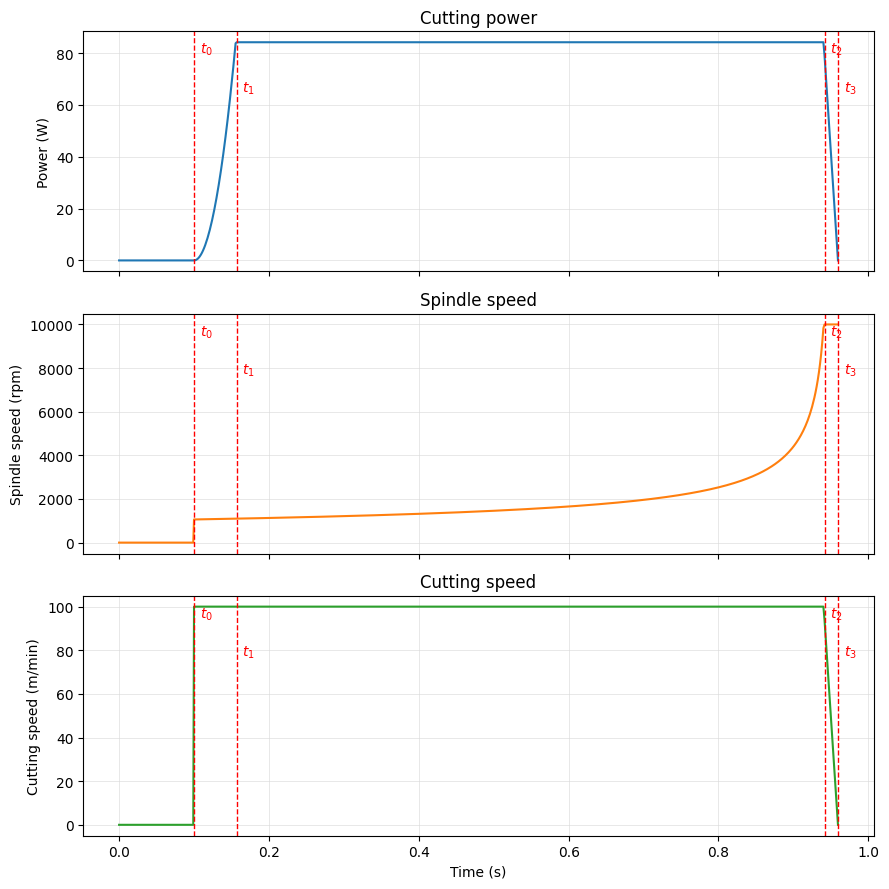

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Cutting power, spindle speed, and cutting speed
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)

axes[0].plot(t, Pc, color='tab:blue')
axes[0].set_ylabel('Power (W)')
axes[0].set_title('Cutting power')

axes[1].plot(t, N_values, color='tab:orange')
axes[1].set_ylabel('Spindle speed (rpm)')
axes[1].set_title('Spindle speed')

axes[2].plot(t, np.array(vc_values) / 1000, color='tab:green')
axes[2].set_ylabel('Cutting speed (m/min)')
axes[2].set_title('Cutting speed')
axes[2].set_xlabel('Time (s)')

for ax in axes:
    for event_time, label, label_height in [
        (t0, r"$t_0$", 0.96),
        (t1, r"$t_1$", 0.80),
        (t2, r"$t_2$", 0.96),
        (t3, r"$t_3$", 0.80),
    ]:
        ax.axvline(event_time, color='red', linestyle='--', linewidth=1)
        ax.annotate(label, xy=(event_time, label_height),
                    xycoords=ax.get_xaxis_transform(), xytext=(4, 0),
                    textcoords='offset points', color='red', va='top')
    ax.set_axisbelow(True)
    ax.grid(True, color='0.85', linewidth=0.6, alpha=0.7)

fig.tight_layout()
plt.show()


## Conclusions

Having **assumed the value of $a_p$** and the shape of the tool (**triangular shape**), is possible to conclude:

* $t_0 \rightarrow t_1$: the tool is being engaged gradually, having $v_c = \text{const}$ and $N \uparrow$

* $t_1 \rightarrow t_2$: fully engagement, having $v_c = \text{const}$ and $N \uparrow$

* $t_2 \rightarrow t_3$: finishing the facing process, having $N = \text{const}$ and $v_c \downarrow$